In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Summary of Weather.csv")

In [3]:
display(df.head())

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
0,10001,1942-7-1,1.016,NaN,25.555556,22.222222,23.888889,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001,1942-7-2,0,NaN,28.888889,21.666667,25.555556,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10001,1942-7-3,2.54,NaN,26.111111,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,1942-7-4,2.54,NaN,26.666667,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10001,1942-7-5,0,NaN,26.666667,21.666667,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 31 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   STA          119040 non-null  int64  
 1   Date         119040 non-null  object 
 2   Precip       119040 non-null  object 
 3   WindGustSpd  532 non-null     float64
 4   MaxTemp      119040 non-null  float64
 5   MinTemp      119040 non-null  float64
 6   MeanTemp     119040 non-null  float64
 7   Snowfall     117877 non-null  object 
 8   PoorWeather  34237 non-null   object 
 9   YR           119040 non-null  int64  
 10  MO           119040 non-null  int64  
 11  DA           119040 non-null  int64  
 12  PRCP         117108 non-null  object 
 13  DR           533 non-null     float64
 14  SPD          532 non-null     float64
 15  MAX          118566 non-null  float64
 16  MIN          118572 non-null  float64
 17  MEA          118542 non-null  float64
 18  SNF          117877 non-

In [5]:
df.head()

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
0,10001,1942-7-1,1.016,NaN,25.555556,22.222222,23.888889,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001,1942-7-2,0,NaN,28.888889,21.666667,25.555556,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10001,1942-7-3,2.54,NaN,26.111111,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,1942-7-4,2.54,NaN,26.666667,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10001,1942-7-5,0,NaN,26.666667,21.666667,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.tail()

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
119035,82506,1945-12-27,0,NaN,28.333333,18.333333,23.333333,0.0,NaN,45,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
119036,82506,1945-12-28,9.906,NaN,29.444444,18.333333,23.888889,0.0,1.0,45,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
119037,82506,1945-12-29,0,NaN,28.333333,18.333333,23.333333,0.0,1.0,45,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
119038,82506,1945-12-30,0,NaN,28.333333,18.333333,23.333333,0.0,NaN,45,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
119039,82506,1945-12-31,0,NaN,29.444444,17.222222,23.333333,0.0,NaN,45,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# veri temizliği yapacğız null olan çok satır var bunları düzeltelim

In [8]:
# 1. İşimize yarayacak anlamlı sütunları seçelim (Bomboş ve tekrar eden sütunları eliyoruz)
# STA: İstasyon kodu, YR: Yıl, MO: Ay, DA: Gün, Precip: Yağış, Snowfall: Kar, MinTemp & MaxTemp: Sıcaklıklarv

In [9]:
secilen_sutunlar = ['STA', 'YR', 'MO', 'DA', 'Precip', 'Snowfall', 'MinTemp', 'MaxTemp']
df_clean = df[secilen_sutunlar].copy()

In [10]:
df_clean['Precip'] = df_clean['Precip'].replace('T', '0')
df_clean['Precip'] = pd.to_numeric(df_clean['Precip'], errors='coerce')

In [11]:
# 3. 'Snowfall' içindeki bozuk metinleri ('#VALUE!' vb.) sayısala çevirelim (bozuk olanlar NaN olur)
df_clean['Snowfall'] = pd.to_numeric(df_clean['Snowfall'], errors='coerce')

In [12]:
# 4. Kalan çok az sayıdaki eksik (NaN) satırı silelim
df_clean.dropna(inplace=True)

In [13]:
print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
Index: 117833 entries, 0 to 119039
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       117833 non-null  int64  
 1   YR        117833 non-null  int64  
 2   MO        117833 non-null  int64  
 3   DA        117833 non-null  int64  
 4   Precip    117833 non-null  float64
 5   Snowfall  117833 non-null  float64
 6   MinTemp   117833 non-null  float64
 7   MaxTemp   117833 non-null  float64
dtypes: float64(4), int64(4)
memory usage: 8.1 MB
None


In [14]:
print(df_clean.info())
print("\nEksik veri sayısı:\n", df_clean.isnull().sum())
display(df_clean.head())

<class 'pandas.core.frame.DataFrame'>
Index: 117833 entries, 0 to 119039
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       117833 non-null  int64  
 1   YR        117833 non-null  int64  
 2   MO        117833 non-null  int64  
 3   DA        117833 non-null  int64  
 4   Precip    117833 non-null  float64
 5   Snowfall  117833 non-null  float64
 6   MinTemp   117833 non-null  float64
 7   MaxTemp   117833 non-null  float64
dtypes: float64(4), int64(4)
memory usage: 8.1 MB
None

Eksik veri sayısı:
 STA         0
YR          0
MO          0
DA          0
Precip      0
Snowfall    0
MinTemp     0
MaxTemp     0
dtype: int64


,STA,YR,MO,DA,Precip,Snowfall,MinTemp,MaxTemp
0,10001,42,7,1,1.016,0.0,22.222222,25.555556
1,10001,42,7,2,0.000,0.0,21.666667,28.888889
2,10001,42,7,3,2.540,0.0,22.222222,26.111111
3,10001,42,7,4,2.540,0.0,22.222222,26.666667
4,10001,42,7,5,0.000,0.0,21.666667,26.666667


In [15]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 117833 entries, 0 to 119039
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       117833 non-null  int64  
 1   YR        117833 non-null  int64  
 2   MO        117833 non-null  int64  
 3   DA        117833 non-null  int64  
 4   Precip    117833 non-null  float64
 5   Snowfall  117833 non-null  float64
 6   MinTemp   117833 non-null  float64
 7   MaxTemp   117833 non-null  float64
dtypes: float64(4), int64(4)
memory usage: 8.1 MB


In [16]:
df_clean.head()

,STA,YR,MO,DA,Precip,Snowfall,MinTemp,MaxTemp
0,10001,42,7,1,1.016,0.0,22.222222,25.555556
1,10001,42,7,2,0.000,0.0,21.666667,28.888889
2,10001,42,7,3,2.540,0.0,22.222222,26.111111
3,10001,42,7,4,2.540,0.0,22.222222,26.666667
4,10001,42,7,5,0.000,0.0,21.666667,26.666667


In [17]:
# Grafik boyutunu ayarlayalım (Yan yana 2 grafik çizeceğiz)
plt.figure(figsize=(16, 6))

<Figure size 1600x600 with 0 Axes>

<Figure size 1600x600 with 0 Axes>

Text(0.5, 1.0, 'Değişkenler Arası Korelasyon Matrisi')

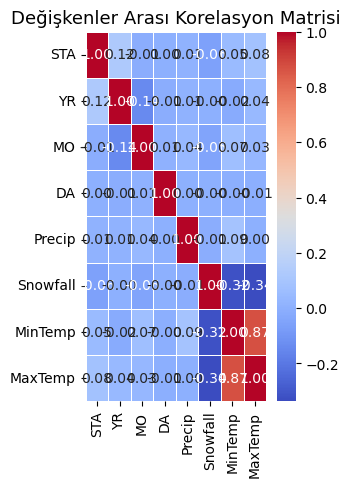

In [18]:
# 1. Grafik: Korelasyon Isı Haritası (Heatmap)
plt.subplot(1, 2, 1)
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Değişkenler Arası Korelasyon Matrisi", fontsize=13)

Text(0, 0.5, 'Maksimum Sıcaklık (MaxTemp)')

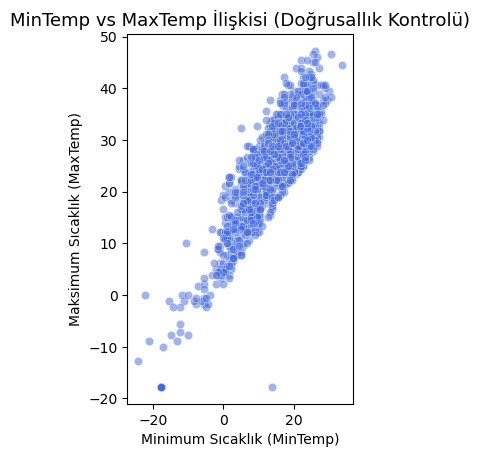

In [19]:
# 2. Grafik: MinTemp vs MaxTemp Dağılım Grafiği (Scatter Plot)
# Not: 117 bin nokta üst üste binmesin diye rastgele 2000 örneklem (sample) alıp çizdiriyoruz
plt.subplot(1, 2, 2)
orneklem = df_clean.sample(n=2000, random_state=42)
sns.scatterplot(data=orneklem, x='MinTemp', y='MaxTemp', alpha=0.5, color='royalblue')
plt.title("MinTemp vs MaxTemp İlişkisi (Doğrusallık Kontrolü)", fontsize=13)
plt.xlabel("Minimum Sıcaklık (MinTemp)")
plt.ylabel("Maksimum Sıcaklık (MaxTemp)")

In [20]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

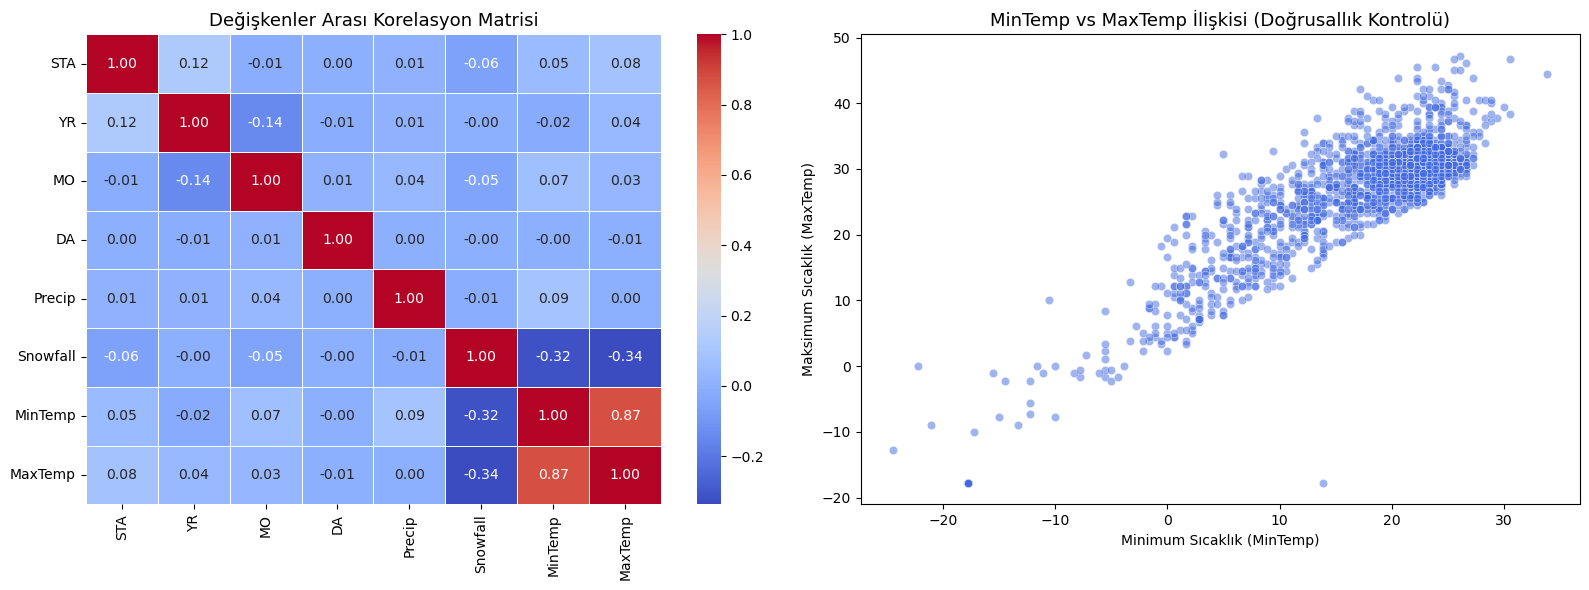

In [21]:
# Grafik boyutunu ayarlayalım (Yan yana 2 grafik çizeceğiz)
plt.figure(figsize=(16, 6))

# 1. Grafik: Korelasyon Isı Haritası (Heatmap)
plt.subplot(1, 2, 1)
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Değişkenler Arası Korelasyon Matrisi", fontsize=13)

# 2. Grafik: MinTemp vs MaxTemp Dağılım Grafiği (Scatter Plot)
# Not: 117 bin nokta üst üste binmesin diye rastgele 2000 örneklem (sample) alıp çizdiriyoruz
plt.subplot(1, 2, 2)
orneklem = df_clean.sample(n=2000, random_state=42)
sns.scatterplot(data=orneklem, x='MinTemp', y='MaxTemp', alpha=0.5, color='royalblue')
plt.title("MinTemp vs MaxTemp İlişkisi (Doğrusallık Kontrolü)", fontsize=13)
plt.xlabel("Minimum Sıcaklık (MinTemp)")
plt.ylabel("Maksimum Sıcaklık (MaxTemp)")

plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [24]:
# 1. Girdiler (X) ve Hedef (y) değişkenini belirleyelim
# Şimdilik en güçlü öznitelik olan MinTemp'i bağımsız değişken (X) yapalım
X = df_clean[['MinTemp']]
y = df_clean['MaxTemp'] # tahmin etmek istediğimiz hedef

# 2. Veriyi %80 Eğitim, %20 Test olarak ayıralım
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Eğitim seti boyutu (X_train):", X_train.shape)
print("Test seti boyutu (X_test):", X_test.shape)

Eğitim seti boyutu (X_train): (94266, 1)
Test seti boyutu (X_test): (23567, 1)


In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [26]:
#Modeli Eğitme ve Sınava Sokma

In [27]:
# 1. Modeli çağıralım ve eğitelim (Makine şu an MinTemp-MaxTemp ilişkisini öğreniyor)
#model = LinearRegression()
#model.fit(X_train, y_train)

LinearRegression()

Modelin Başarı Skoru (R2): 0.7543
Ortalama Kare Hata (MSE): 17.20


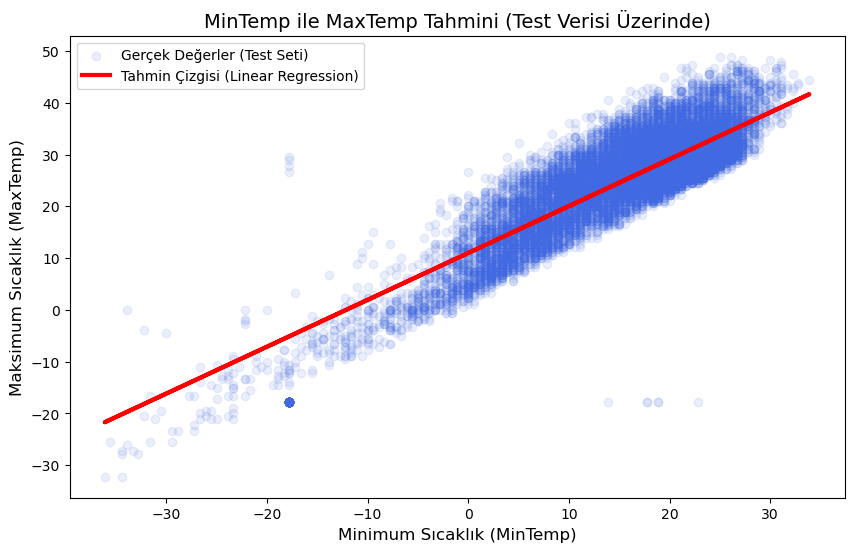

In [28]:
# 1. Modeli çağıralım ve eğitelim (Makine şu an MinTemp-MaxTemp ilişkisini öğreniyor)
model = LinearRegression()
model.fit(X_train, y_train)

# 2. Test seti üzerinde tahmin yaptıralım 
y_pred = model.predict(X_test)

# 3. Başarı metriklerini hesaplama
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"Modelin Başarı Skoru (R2): {r2:.4f}")
print(f"Ortalama Kare Hata (MSE): {mse:.2f}")

# 4. Gerçek değerlerin üzerine modelin çizdiği regresyon doğrusunu ekleyelim
plt.figure(figsize=(10,6))
# Gerçek verileri (Mavi noktalar) çizdiriyoruz. Çok kalabalık olmasın diye test setinden örneklem alabiliriz
# ama test setinin tamamını da çizdirebiliriz.
plt.scatter(X_test, y_test, color='royalblue', alpha=0.1, label='Gerçek Değerler (Test Seti)')

# Modelin tahmin çizgisini (Kırmızı doğru) çizdiriyoruz
plt.plot(X_test, y_pred, color='red', linewidth=3, label='Tahmin Çizgisi (Linear Regression)')
plt.title("MinTemp ile MaxTemp Tahmini (Test Verisi Üzerinde)", fontsize=14)
plt.xlabel("Minimum Sıcaklık (MinTemp)", fontsize=12)
plt.ylabel("Maksimum Sıcaklık (MaxTemp)", fontsize=12)
plt.legend()
plt.show()

In [29]:
import os
print(os.getcwd())

C:\Users\SINANKABAK\PythonProjects\MachineLearning
